In [1]:
#import corner
import numpy as np
import random
import pandas as pd
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib import dates
from sklearn.metrics import mean_squared_error, r2_score
from datetime import datetime
from lmfit import Minimizer, Parameters, Parameter, report_fit, printfuncs, conf_interval,minimize
from statsmodels.tsa.arima_model import ARIMA

# step 0: data importation #

In [4]:
csv_url="https://raw.githubusercontent.com/ADelau/proj0016-epidemic-data/main/data.csv"
data = pd.read_csv(csv_url)
data['day_hospitalization']=data['num_cumulative_hospitalizations'].diff().shift(periods=-1)

In [5]:
data.head()

,Day,num_positive,num_tested,num_hospitalised,num_cumulative_hospitalizations,num_critical,num_fatalities,day_hospitalization
0,1,0,0,1,1,0,0,0.0
1,2,5,8,1,1,0,0,1.0
2,3,10,12,2,2,0,0,0.0
3,4,11,16,2,2,0,0,0.0
4,5,9,12,2,2,0,0,0.0


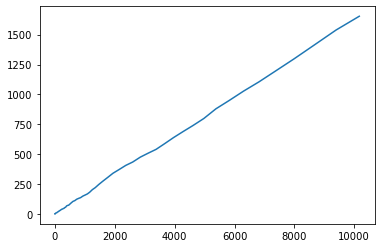

In [6]:
plt.plot(data['num_hospitalised'].cumsum(),data['num_cumulative_hospitalizations'])

# step 1: setting up the model #

In [24]:
# the lmfit module uses an orderd dict structure
# to store the parameters to be optimized
# https://lmfit.github.io/lmfit-py/parameters.html

params = Parameters()
params.add('beta_SI', value=0.15, min=0.02, max=1)
params.add('gamma_IR', value= 0.05, min=0.02, max=1)


#params.add('S0',value=5,min=1,max=20)
params.add('I0',value=20,min=4,max=200)
#params.add('R0',value=5,min=0,max=20)



params.add('O_nbtest_SI',value=0.25,min=0.05,max=1)
params.add('O_dailyH_IR',value =7.5, min=1.5, max=20)


params.add('Tr_I_H', value=0.02,min=0.001,max=0.1)
params.add('Tr_H_R', value=0.5,min=0.01,max=1)

params.add('P_trIHcum_ICUcum',value=0.66, min=0.2,max=1.2)
#params.add('P_ICUcum_D',value=0.0002, min=0.00002,max=0.0004)
params.add('P_trIHcum_D',value=0.01,min=0.0001,max=1)
#params.add('P_H_Hcum',value=2,min=1.75,max=2.5)
params.add('ratio_pos_tested',value=0.75,min=0.6,max=0.9)


# params.add('OBS_H_to_ICU',value=0.1,min=0.01,max=0.5) mistake??

In [25]:
def deriv(compartiments, t, params):
    S,I,R,H = compartiments
    beta_SI = params['beta_SI'].value
    gamma_IR = params['gamma_IR'].value
    Tr_I_H = params['Tr_I_H'].value
    Tr_H_R = params['Tr_H_R'].value

    #beta = beta_i*(1.1-tau*t) idée de faire régresser beta
    dSdt = -beta_SI*(S*I/(1e6))
    dIdt = beta_SI*(S*I/(1e6)) - gamma_IR*I - Tr_I_H*I
    dRdt = gamma_IR*I + Tr_H_R*H
    dHdt = Tr_I_H*I - Tr_H_R*H
    
    
    
    return dSdt, dIdt, dRdt, dHdt

## step 2: create compartimental functions ##

In [26]:
""" This function generates a dataframe from the data
input: dataframe from data.csv, parameters params
output: a dataframe with compartiment numbers and transitions
"""

def data2comp(params,data):

    result=pd.DataFrame()
    result['Day']=data['Day']
    result['S->I']=params['O_nbtest_SI'].value*data['num_tested']
    result['I->H']=data['num_cumulative_hospitalizations'].diff()
    result['I->H'][0]=0
    result['I->R']=params['O_dailyH_IR']*result['I->H']
    result['I->R'][0]=0
    result['H->R']=data['num_cumulative_hospitalizations'].diff()-data['num_hospitalised'].diff()
    result['H->R'][0]=0
    
    result['I']=params['I0'].value+result['S->I'].cumsum()-result['I->H'].cumsum()
    result['I'][0]=params['I0'].value
    #result['dH']=data['num_cumulative_hospitalizations'].diff()
    result['H']=data['num_hospitalised']
    result['ICU']=data['num_critical']
    result['D']=data['num_fatalities']
    result['R']=result['I->R'].cumsum()+result['H->R'].cumsum()
    result['R'][0]=0
    result['S']=(1e6-result['I']-result['R']-result['H']-result['ICU']-result['D'])-result['S->I'].cumsum()
    #result['Rnumber']=1e6*result['S->I']/(result['S']*result['I->R'])
    result['pos/tested']=data['num_positive']/data['num_tested']
    
    return result 
    

In [27]:
"""
this function creates a dataframe from parameters (data just for timespan)
input: clinical dataframe, parameters
output: a dataframe with compartiment numbers and transitions
"""
#timespan=np.linspace(0,data.shape[0]-1,data.shape[0])
def params2comp(params,timespan):
    

    result=pd.DataFrame()
    result['Day']=timespan
    array=odeint(deriv,[1e6-params['I0'].value,params['I0'].value,0,0],timespan, args=(params,))
    result['S']=array.transpose()[0]
    result['I']=array.transpose()[1]
    result['R']=array.transpose()[2]
    result['H']=array.transpose()[3]
    result['S->I']=params['beta_SI'].value*(result['S']*result['I']/(1e6))
    result['I->H']=params['Tr_I_H']*result['I']
    result['I->R']=params['gamma_IR'].value*result['I']
    result['H->R']=params['Tr_H_R'].value*result['H']
    #cumH=result['H'].cumsum()
    cumICU=params['P_trIHcum_ICUcum'].value*result['I->H'].cumsum()
    #D=params['P_ICUcum_D'].value*cumICU
    D=params['P_trIHcum_D'].value*result['I->H'].cumsum()
    result['ICU']=cumICU.diff()
    result['ICU'][0]=0
    result['D']=D
    result['pos/tested']=params['ratio_pos_tested'].value
    #result['Rnumber']=result['S->I']/(result['S']*result['I->R'])
    
    return result
    

In [28]:
def params2obs(params,timespan):
    result=pd.DataFrame()
    result['Day']=timespan
    
    comp_df=params2comp(params,timespan)
    result['num_positive']=params['ratio_pos_tested']*comp_df['S->I']/params['O_nbtest_SI'].value
    result['num_tested']=comp_df['S->I']/params['O_nbtest_SI'].value
    result['num_hospitalised']=comp_df['H']
    # H CUM A VERIFIER!!!!
    result['num_cumulative_hospitalizations']=comp_df['I->H'].cumsum()
    result['num_critical']=comp_df['ICU']
    result['num_fatalities']=comp_df['D']
    
    return result
    

In [29]:
tspan=np.linspace(0,data.shape[0]-1,data.shape[0])

In [31]:
params2comp(params,tspan)

,Day,S,I,R,H,S->I,I->H,I->R,H->R,ICU,D,pos/tested
0,0.0,999980.000000,20.000000,0.000000,0.000000,2.999940,0.400000,1.000000,0.000000,0.000000,0.004000,0.75
1,1.0,999976.876807,21.665671,1.128724,0.328797,3.249776,0.433313,1.083284,0.164398,0.285987,0.008333,0.75
2,2.0,999973.493516,23.470054,2.480824,0.555606,3.520415,0.469401,1.173503,0.277803,0.309805,0.013027,0.75
3,3.0,999969.828467,25.424698,4.023999,0.722836,3.813590,0.508494,1.271235,0.361418,0.335606,0.018112,0.75
4,4.0,999965.858201,27.542114,5.743285,0.856400,4.131176,0.550842,1.377106,0.428200,0.363556,0.023621,0.75
...,...,...,...,...,...,...,...,...,...,...,...,...
66,66.0,992729.087189,3874.758024,3262.321146,133.833641,576.987749,77.495160,193.737901,66.916820,51.146806,10.097844,0.75
67,67.0,992128.914286,4192.713561,3533.536541,144.835612,623.956853,83.854271,209.635678,72.417806,55.343819,10.936387,0.75
68,68.0,991479.931399,4536.335143,3827.004369,156.729090,674.652788,90.726703,226.816757,78.364545,59.879624,11.843654,0.75
69,69.0,990778.273561,4907.621952,4144.520385,169.584103,729.354781,98.152439,245.381098,84.792051,64.780610,12.825178,0.75


In [32]:
data2comp(params,data)

<ipython-input-26-e13221496c22>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['I->H'][0]=0
<ipython-input-26-e13221496c22>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['I->R'][0]=0
<ipython-input-26-e13221496c22>:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['H->R'][0]=0
<ipython-input-26-e13221496c22>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See t

,Day,S->I,I->H,I->R,H->R,I,H,ICU,D,R,S,pos/tested
0,1,0.00,0.0,0.0,0.0,20.00,1,0,0,0.0,999979.0,NaN
1,2,2.00,0.0,0.0,0.0,22.00,1,0,0,0.0,999975.0,0.625000
2,3,3.00,1.0,7.5,0.0,24.00,2,0,0,7.5,999961.5,0.833333
3,4,4.00,0.0,0.0,0.0,28.00,2,0,0,7.5,999953.5,0.687500
4,5,3.00,0.0,0.0,0.0,31.00,2,0,0,7.5,999947.5,0.750000
...,...,...,...,...,...,...,...,...,...,...,...,...
66,67,485.50,91.0,682.5,54.0,5483.25,555,55,38,9612.0,977597.5,0.798146
67,68,532.75,100.0,750.0,47.0,5916.00,608,57,39,10409.0,975779.0,0.797278
68,69,562.25,115.0,862.5,52.0,6363.25,671,62,41,11323.5,973785.0,0.799911
69,70,593.00,127.0,952.5,60.0,6829.25,738,67,41,12336.0,971641.5,0.794266


In [33]:
data.head(1)

,Day,num_positive,num_tested,num_hospitalised,num_cumulative_hospitalizations,num_critical,num_fatalities,day_hospitalization
0,1,0,0,1,1,0,0,NaN


In [34]:
def residual(params,timespan,data):
    real=data2comp(params,data)
    sim=params2comp(params,timespan)
    
    obs=params2obs(params,timespan)
    #result_array=np.concatenate([(sim['S->I']-sim['I->H']-sim['I->R'])/sim['I']-(real['S->I']-real['I->H']-real['I->R'])/real['I'],
     #                            sim['ICU'].cumsum()/sim['H'].cumsum()-real['ICU'].cumsum()/real['H'].cumsum(),
      #                           sim['H'][20:].cumsum()/(sim['I'][20:]+sim['R'][20:])-real['H'][20:].cumsum()/(real['I'][20:]+real['R'][20:]),
       #                          sim['D'][20:]/sim['H'][20:].cumsum()-real['D'][20:]/real['H'][20:].cumsum(),
       #                          sim['pos/tested'][20:]-real['pos/tested'][20:]])
    
    result_array=np.concatenate([data['num_positive']-obs['num_positive'], data['num_tested']-obs['num_tested'],
                               data['num_hospitalised']-obs['num_hospitalised'],
                                 data['num_cumulative_hospitalizations']-obs['num_cumulative_hospitalizations'],
                                data['num_critical']-obs['num_critical'],data['num_fatalities']-obs['num_fatalities']])
    
    return result_array[~(np.isnan(result_array))] 
    

In [37]:
mini = Minimizer(residual, params,(tspan,data,))
result = mini.minimize(method='nelder')

#print(lmfit.fit_report(result.params))

<ipython-input-26-e13221496c22>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['I->H'][0]=0
<ipython-input-26-e13221496c22>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['I->R'][0]=0
<ipython-input-26-e13221496c22>:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['H->R'][0]=0
<ipython-input-26-e13221496c22>:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See t

In [38]:
result

In [18]:
timespan_100=np.linspace(0,70,71)

In [19]:
sim_70=params2obs(result.params,np.linspace(0,70,71))
sim_100=params2obs(result.params,np.linspace(0,100,101))
sim_130=params2obs(result.params,np.linspace(0,130,131))

NameError: name 'result' is not defined

In [ ]:
data.tail(5)

In [ ]:
def plotwave(df):
    y=df['num_positive']
    x=df['num_positive'].cumsum()
    plt.loglog(x,y)

In [ ]:
plotwave(sim_130);
plotwave(data)

In [ ]:
plt.plot(sim_70['num_critical'],label='sim');
plt.plot(data['num_critical'],label='data')


In [ ]:
verif1=data2comp(result.params,data)
verif2=params2comp(result.params,np.linspace(0,70,71))

In [ ]:
plt.plot(verif1['ICU'].cumsum());
plt.plot(verif2['ICU'].cumsum());

In [ ]:
verif2

### simulations ###